# Model B v2: deciding what to fix first

**IRIS · Team Nex · PJDSC 2026**

Model A says *which reports look wrong*. Model B answers the next question: **with only a few staff hours this
week, which calls and visits restore the most missing reports?**

The original Model B (`MODEL B/IRIS_Model_B.ipynb`, kept unchanged) was a second detector. It ranked zero reports
from the raw file. Model B v2 is the planner the proposal describes. It reads Model A's output, knows which
facilities share a hub or a lab, and picks actions with an integer program within a staff budget.

Everything here uses the tested code in `pipeline/iris_pipeline/`; numbers match `pipeline/outputs/model_b/report_b.md`.

**Contents**
1. The original Model B on the real errors
2. A simulated reporting network
3. Simulating a year of failures
4. Why the network matters for detection
5. How Model B v2 decides: a worked example
6. Recovery simulation: network-aware vs facility-by-facility
7. A real 2020 plan

In [1]:
# Find the tested pipeline (works in PJDS/ and in the IRIS repo's "models/" folder) and load it.
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
PIPELINE = None
for base in [Path.cwd(), *Path.cwd().parents]:
    for cand in (base / "pipeline", base / "models" / "pipeline", base / "MODEL A" / "pipeline"):
        if (cand / "iris_pipeline").is_dir():
            PIPELINE = cand
            break
    if PIPELINE:
        break
if PIPELINE is None:
    raise FileNotFoundError("Can't find the pipeline/ folder. Open this notebook from inside the repository.")
sys.path.insert(0, str(PIPELINE))

import iris_pipeline  # sets single-threaded maths before numpy loads
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from iris_pipeline import config, data
from iris_pipeline.paths import MODEL_A_V2_DIR, OUT_DIR, V1_OUT_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
print("pipeline:", PIPELINE)
print("outputs: ", OUT_DIR)

pipeline: C:\Users\John Vincent Doria\Desktop\PJDS\pipeline
outputs:  C:\Users\John Vincent Doria\Desktop\PJDS\pipeline\outputs


In [2]:
# The heavy runs live in the pipeline (python -m iris_pipeline all, about 25 min).
# This notebook reads their saved outputs and runs only small live demos. Set to True to rebuild everything first.
RUN_PIPELINE = False
if RUN_PIPELINE:
    from iris_pipeline.cli import main
    main(["all"])

## 1. The original Model B on the real errors

The original rule scores zero reports as 70% × rank of the 26-week average + 30% × rank of the zero streak, ranked
against the other zeros of the same date. Below it is graded on the 158 real swapped reports of 2020, as published
and in a fixed form (clean data, calendar weeks, absolute rather than same-date ranks), next to Model A v2.

In [3]:
ob = pd.read_csv(OUT_DIR / "model_b" / "old_model_b_real_eval.csv")
display(ob[["method", "AUC, 2020 swapped zeros vs normal zeros", "AUC, 2020 all swaps vs all normal weeks",
            "recall at 1% budget (2020 swaps)", "false-alert rate (2020 normal weeks)", "precision", "can see partial reports (1-3 cases)"]])

,method,"AUC, 2020 swapped zeros vs normal zeros","AUC, 2020 all swaps vs all normal weeks",recall at 1% budget (2020 swaps),false-alert rate (2020 normal weeks),precision,can see partial reports (1-3 cases)
0,"Old Model B, as published (within-date ranks)",0.517,0.905,0.285,0.047,0.132,no (zeros only)
1,"Old Model B, fixed (absolute)",0.390,0.881,0.329,0.095,0.079,no (zeros only)
2,Model A v2,0.656,0.790,0.089,0.055,0.039,yes


**Reading it.** Among zero reports the published rule is a coin flip (AUC 0.52): it ranks a zero against other
zeros of the same date, so a whole region dropping to zero can't stand out. Yet 157 of the 158 real 2020 swaps are
zeros, and simply being a zero is strong evidence, so at the alarm budget the rule still catches more of them than
Model A v2. It cannot see partial reports, and it has no notion of staff time, actions or shared causes. Model B
v2 therefore stops detecting and starts planning.

## 2. A simulated reporting network

Real reporting pathways are not available, so a **fictional** network is laid over the real 126 provinces and
cities: facilities report through provincial **hubs** to their region's **RESU**, and send specimens to **labs**.
Each facility's weekly counts are a random split of its location's real dengue counts, so levels and seasons are
realistic while every failure is known exactly.

In [4]:
from iris_pipeline.network.build import build_world

world = build_world()
display(world.nodes.node_type.value_counts().rename("nodes").to_frame())
fac = world.facilities
print(f"Facilities per hub: median {fac.groupby('hub_id').size().median():.0f}; per lab: median {fac.groupby('lab_id').size().median():.0f}")
display(fac[fac.region_id == "NCR"].head(8))

,nodes
node_type,
facility,506
hub,70
lab,36
resu,17


Facilities per hub: median 6; per lab: median 14


,facility_id,location_id,region_id,hub_id,lab_id,share
73,FAC-NCR-PASAY_CITY-1,NCR-PASAY_CITY,NCR,HUB-NCR-01,LAB-NCR-3,0.360
74,FAC-NCR-PASAY_CITY-2,NCR-PASAY_CITY,NCR,HUB-NCR-01,LAB-NCR-1,0.318
75,FAC-NCR-PASAY_CITY-3,NCR-PASAY_CITY,NCR,HUB-NCR-01,LAB-NCR-1,0.322
76,FAC-NCR-TAGUIG_CITY-1,NCR-TAGUIG_CITY,NCR,HUB-NCR-02,LAB-NCR-1,0.308
77,FAC-NCR-TAGUIG_CITY-2,NCR-TAGUIG_CITY,NCR,HUB-NCR-02,LAB-NCR-1,0.132
78,FAC-NCR-TAGUIG_CITY-3,NCR-TAGUIG_CITY,NCR,HUB-NCR-02,LAB-NCR-3,0.356
79,FAC-NCR-TAGUIG_CITY-4,NCR-TAGUIG_CITY,NCR,HUB-NCR-02,LAB-NCR-3,0.204
80,FAC-NCR-MALABON_CITY-1,NCR-MALABON_CITY,NCR,HUB-NCR-02,LAB-NCR-1,0.091


## 3. Simulating a year of failures

Each simulated year has three kinds of failure:
- **isolated**: one facility reports zero or part of its cases;
- **hub**: every facility behind a hub reports zero or a small part (a shared outage);
- **lab**: facilities sending specimens to a failing lab lose part of their confirmed cases.

Failures end on their own after a random number of weeks, or earlier if the right action succeeds. Below: one
simulated year, and what a partial hub outage looks like in the reports.

,events,facilities,mean_weeks
kind,,,
hub,6,32,5.333
isolated,40,40,4.300
lab,3,44,4.000


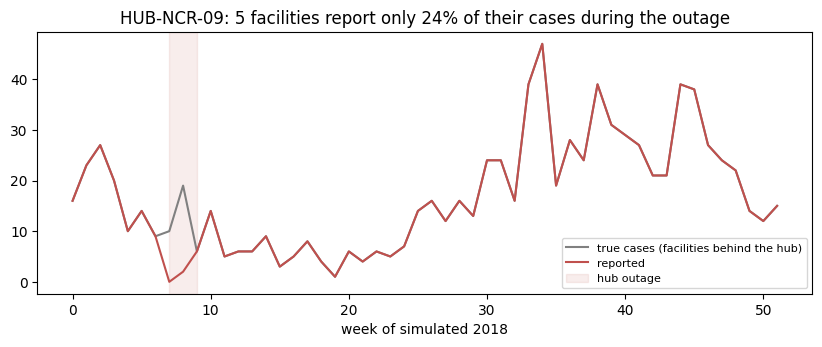

In [5]:
from iris_pipeline.network.simulate import Simulation, draw_events, events_frame

seed, year = config.SIM["TEST_SEEDS"][0], config.SIM["TEST_YEAR"]
w = world.resample(seed)
events = draw_events(w, year, seed)
ev = events_frame(events, w)
display(ev.groupby("kind").agg(events=("event_id", "size"), facilities=("n_facilities", "sum"),
                               mean_weeks=("end_week_if_unrepaired", lambda s: (s - ev.loc[s.index, "start_week"]).mean())))
hub_ev = next(e for e in events if e.kind == "hub" and e.mult > 0)
sim = Simulation(w, year, events, seed)
true = np.array([sim.true(t)[hub_ev.members].sum() for t in range(sim.n_weeks)])
obs = np.array([sim.observed(t)[hub_ev.members].sum() for t in range(sim.n_weeks)])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(true, color="grey", label="true cases (facilities behind the hub)")
ax.plot(obs, color="#c0504d", label="reported")
ax.axvspan(hub_ev.start, hub_ev.end, color="#c0504d", alpha=0.1, label="hub outage")
ax.set_xlabel(f"week of simulated {year}")
ax.set_title(f"{hub_ev.source}: {len(hub_ev.members)} facilities report only {hub_ev.mult:.0%} of their cases during the outage")
ax.legend(fontsize=8)
plt.show()

## 4. Why the network matters for detection

Model A v2 scores each facility. During a partial hub outage each facility's drop can look like ordinary noise,
but together they are unmistakable. The **summed-count test** adds up what the facilities behind a hub reported
and compares it with what the model expected for all of them, allowing for the fact that their counts move together.

In [6]:
import pickle
from iris_pipeline.network.scorer import FacilityModels
from iris_pipeline.network.sources import Sources

tuned_path = OUT_DIR / "network" / "tuned.pkl"   # thresholds tuned on separate replicates (written by model-b)
if tuned_path.exists():
    tuned = pickle.load(open(tuned_path, "rb"))
    tau_fac, tau_hub, rho = tuned["tau_fac"], tuned["tau_src"][("graph: hub + lab, NB sum", "hub")], tuned["rho"]
else:  # values from report_b.md, if the pickle was not synced
    tau_fac, tau_hub, rho = 0.0105, 0.019, {"hub": 0.29, "lab": 0.18, "region": 0.19}
    print("tuned.pkl not found: using the thresholds printed in report_b.md")

inp = data.load(check=False)
src = Sources(w)
fm = FacilityModels(w, year, inp.cal)   # Model A v2 per facility, fitted on the 2 years before the simulated year
st = fm.new_state()
weeks = [fm.score(t, sim.observed(t), st) for t in range(sim.n_weeks)]   # no repairs: failures run their course
p_src = np.array([src.nb_sum(r, rho) for r in weeks])

caught, example = 0, None
for e in (e for e in events if e.kind == "hub"):
    s_idx = src.index[e.source]
    hit = [t for t in range(e.start, e.end) if p_src[t, s_idx] < tau_hub]
    caught += bool(hit)
    for t in hit:
        alone = int((np.nan_to_num(weeks[t]["p_low"][e.members], nan=1) < tau_fac).sum())
        if example is None and alone <= len(e.members) // 2:
            example = (e, t, alone)
print(f"In this simulated year the summed test caught {caught} of 6 hub outages while they were happening.")
if example:
    e, t, alone = example
    r = weeks[t]
    display(Markdown(f"**Example: {e.source}, week {t}** ({len(e.members)} facilities, reporting {e.mult:.0%} of their cases)"))
    display(pd.DataFrame({"facility": w.facilities.facility_id.to_numpy()[e.members], "reported": r["y"][e.members],
                          "expected": r["mu"][e.members].round(1), "p_low (this facility alone)": r["p_low"][e.members]}))
    print(f"Facilities flagged on their own (p_low < {tau_fac:.3g}): {alone} of {len(e.members)}")
    print(f"Summed test for the hub: p = {p_src[t, src.index[e.source]]:.1e} (threshold {tau_hub:.2g}) -> hub flagged as the likely shared cause")

In this simulated year the summed test caught 4 of 6 hub outages while they were happening.


**Example: HUB-R05-04, week 19** (6 facilities, reporting 0% of their cases)

,facility,reported,expected,p_low (this facility alone)
0,FAC-R05-NAGA_CITY-1,0.0,2.4,9.609e-02
1,FAC-R05-NAGA_CITY-2,0.0,8.3,8.009e-04
2,FAC-R05-NAGA_CITY-3,0.0,2.6,8.261e-02
3,FAC-R05-CAMARINES_NORTE-1,0.0,0.5,3.360e-01
4,FAC-R05-CAMARINES_NORTE-2,0.0,1.9,1.248e-01
5,FAC-R05-CAMARINES_NORTE-3,0.0,1.2,1.719e-01


Facilities flagged on their own (p_low < 0.0105): 1 of 6
Summed test for the hub: p = 1.5e-04 (threshold 0.019) -> hub flagged as the likely shared cause


**Graph ablation over 20 simulated years** (mean and 95% interval)

,hub source identified,lab source identified,facility-week recall,facility-week false-alert rate
method,,,,
facility only (no graph),0% (0%-0%),0% (0%-0%),14% (12%-16%),0% (0%-0%)
region pooling (no graph),0% (0%-0%),0% (0%-0%),24% (19%-28%),3% (3%-3%)
"graph: hub + lab, Stouffer",55% (48%-62%),40% (28%-52%),36% (30%-43%),3% (3%-3%)
"graph: hub + lab, NB sum",72% (64%-80%),35% (23%-47%),40% (33%-46%),2% (2%-2%)


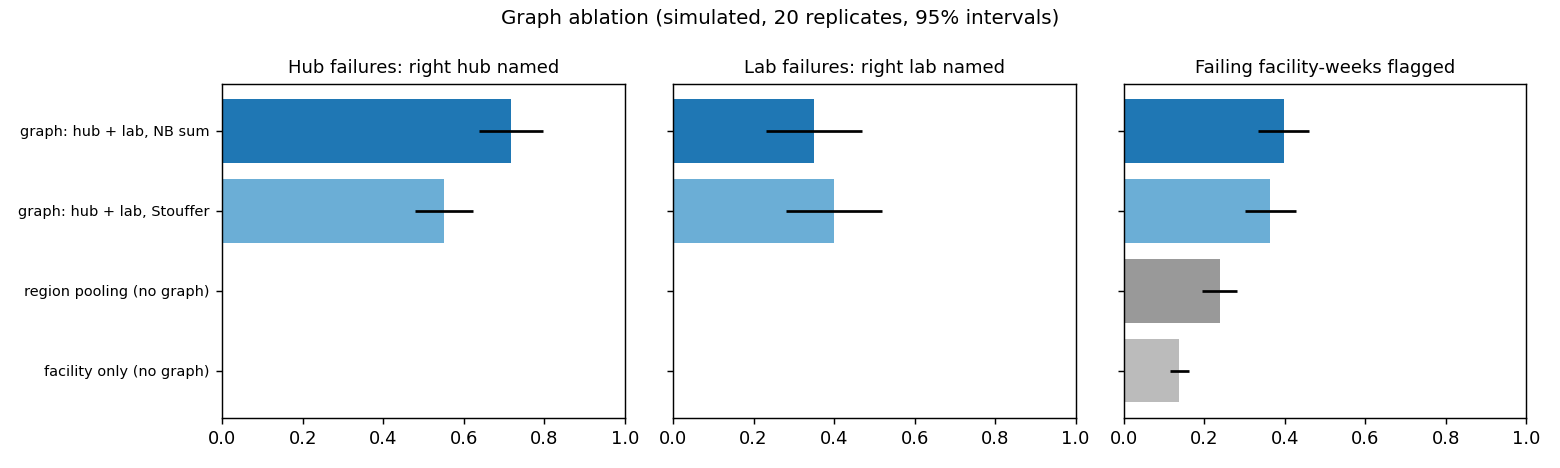

In [7]:
b = json.loads((OUT_DIR / "model_b" / "metrics_b.json").read_text(encoding="utf-8"))
fmt = lambda v: f"{v[0]:.0%} ({v[1]:.0%}-{v[2]:.0%})" if isinstance(v, list) and v[0] is not None else ""
abl = pd.DataFrame(b["ablation"])[["method", "hub source identified", "lab source identified", "facility-week recall",
                                    "facility-week false-alert rate"]]
display(Markdown("**Graph ablation over 20 simulated years** (mean and 95% interval)"))
display(abl.set_index("method").map(fmt))
display(Image(filename=str(OUT_DIR / "model_b" / "figures" / "1_graph_ablation.png"), width=900))

## 5. How Model B v2 decides: a worked example

Each action has a cost in staff hours (taken from the IRIS backend planner) and a chance of success. Its value is
the expected number of failed weekly reports it restores:

`value = success chance × chance the problem is really there × weeks the failure would otherwise last`

The integer program picks the set of actions with the highest total value within the hours, and never counts a
facility twice (fixing its hub already restores it).

Example: a hub serving 6 facilities is probably down (probability 0.6), and 3 of those facilities also look bad on
their own. There are 20 staff hours. Fixing the hub takes 16 of them; calling a facility takes 2.

In [8]:
from iris_pipeline.model_b.actions import make
from iris_pipeline.model_b.optimizer import objective, solve

hub_fac = np.arange(6)
acts = [make("fix_hub", "HUB-X", 6, hub_fac, np.full(6, 0.6))]
for i in (0, 1, 2):  # facility calls: p_fail 0.7, but 60% of that is explained by the hub
    acts.append(make("call_facility", f"FAC-{i}", 1, [i], [0.7 * (1 - 0.6)]))
chosen, value = solve(acts, hours=20, cost=1e9)
display(pd.DataFrame([{"action": a.action, "target": a.target, "hours": a.hours, "value (reports restored)": round(a.value, 2),
                       "chosen": i in chosen} for i, a in enumerate(acts)]))
calls_only = [1, 2, 3]
print(f"Integer program: {value:.2f} expected reports restored with {sum(acts[i].hours for i in chosen)} h")
print(f"Calling the 3 facilities instead: {objective(acts, calls_only):.2f} with {sum(acts[i].hours for i in calls_only)} h")
print("The facility calls add nothing once the hub is fixed (the hub fix already restores them), so the program skips them.")

,action,target,hours,value (reports restored),chosen
0,fix_hub,HUB-X,16.0,14.40,True
1,call_facility,FAC-0,2.0,0.62,False
2,call_facility,FAC-1,2.0,0.62,False
3,call_facility,FAC-2,2.0,0.62,False


Integer program: 14.40 expected reports restored with 16.0 h
Calling the 3 facilities instead: 1.85 with 6.0 h
The facility calls add nothing once the hub is fixed (the hub fix already restores them), so the program skips them.


## 6. Recovery simulation: network-aware vs facility-by-facility

Twenty simulated years. Each week: reports arrive → Model A scores every facility → shared-source tests → the
policy picks actions within 24 staff hours → each action succeeds or fails (the same luck for every policy) →
repaired failures end the next week.

,recovered submissions,recovered per staff-hour,mean weeks to recover (shared failures),shared source acted on first
policy,,,,
Network-aware (Model B v2),176.10 (131.62-220.58),0.14 (0.11-0.18),2.71 (2.34-3.07),0.84 (0.78-0.90)
Facility-first (proposal baseline),29.15 (24.02-34.28),0.02 (0.02-0.03),4.68 (4.24-5.12),0.00 (0.00-0.00)
"Old Model B rule, fixed",35.50 (28.53-42.47),0.03 (0.02-0.03),4.68 (4.24-5.12),0.00 (0.00-0.00)
Random,10.50 (7.90-13.10),0.01 (0.01-0.01),4.68 (4.24-5.12),0.00 (0.00-0.00)
Oracle (knows the truth),333.00 (289.89-376.11),0.72 (0.63-0.81),1.60 (1.39-1.81),1.00 (1.00-1.00)


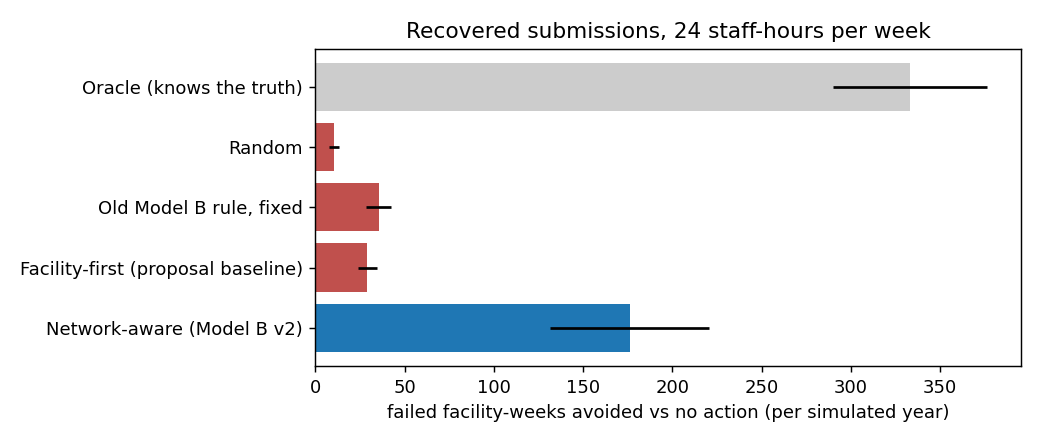

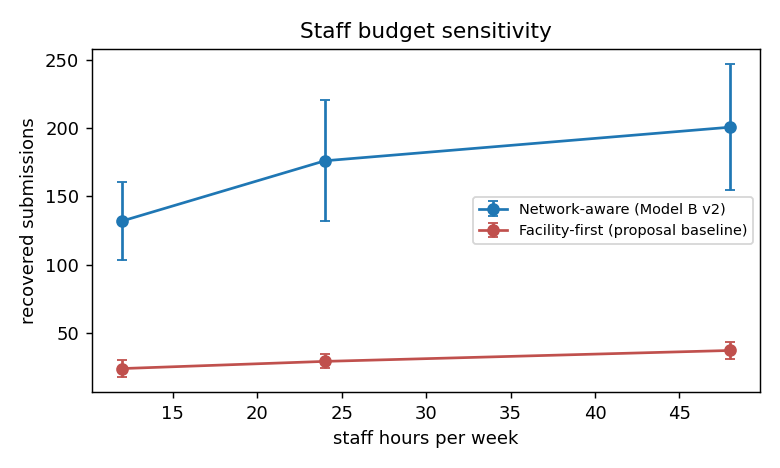

In [9]:
rec = pd.DataFrame(b["recovery"])
r24 = rec[rec["staff hours / week"] == config.PLAN["STAFF_HOURS_PER_WEEK"]]
cols = ["policy", "recovered submissions", "recovered per staff-hour", "mean weeks to recover (shared failures)", "shared source acted on first"]
f2 = lambda v: f"{v[0]:.2f} ({v[1]:.2f}-{v[2]:.2f})" if isinstance(v, list) and v[0] is not None else ""
display(r24[cols].set_index("policy").map(f2))
display(Image(filename=str(OUT_DIR / "model_b" / "figures" / "2_policy_recovered.png"), width=780))
display(Image(filename=str(OUT_DIR / "model_b" / "figures" / "3_hours_sensitivity.png"), width=520))

With the same staff time, network-aware planning restores about **6×** more failed weekly reports than calling
facilities one by one. It reaches the shared cause first in most shared failures, and shared failures end about
two weeks sooner. An oracle that knows every failure restores about twice as much again; most of that gap is in
detection, not in planning.

## 7. A real 2020 plan

On the real data, provinces and cities stand in for facilities and each region's RESU for its hub. For one week,
Model B v2 builds the plan live at three staff budgets. Values are in **cases likely missing** that a successful
action would bring back.

In [10]:
from iris_pipeline.model_a.v2 import read_scores
from iris_pipeline.model_b.real_plan import dengue_rows, plan_rows, region_calibrator, week_candidates

d = dengue_rows(read_scores(MODEL_A_V2_DIR / "scores_v2.csv"))
cal = region_calibrator(d, inp.Y_dengue)
g, acts = week_candidates(d[d.period_start == "2020-11-15"], cal)
summary = []
for hours in (12, 24, 48):
    chosen, value = solve(acts, float(hours), config.PLAN["COST_PHP_PER_WEEK"])
    summary.append({"staff hours": hours, "actions": len(chosen), "hours used": sum(acts[i].hours for i in chosen),
                    "expected cases recovered": round(value, 1)})
display(pd.DataFrame(summary))
chosen, _ = solve(acts, config.PLAN["STAFF_HOURS_PER_WEEK"], config.PLAN["COST_PHP_PER_WEEK"])
plan = pd.DataFrame(plan_rows(g, acts, chosen, "notebook"))
display(plan[["action", "target", "hours", "expected_cases_recovered", "missing_reports", "reported_cases", "expected_cases",
              "p_fail_max", "P_region", "status"]])
resu = plan[plan.action == "call_resu"]
print(f"{len(resu)} RESU checks covering {int(resu.missing_reports.sum())} locations whose report never arrived; "
      f"{int((plan.action == 'call_location').sum())} single-location calls.")

,staff hours,actions,hours used,expected cases recovered
0,12,3,11.5,32.0
1,24,4,23.5,62.0
2,48,13,46.5,73.8


,action,target,hours,expected_cases_recovered,missing_reports,reported_cases,expected_cases,p_fail_max,P_region,status
0,call_resu,RESU-NCR,10.0,28.43,17,0,51.7,NaN,1.0,lead to verify
1,call_resu,RESU-R12,4.5,21.06,6,0,38.3,NaN,1.0,lead to verify
2,call_resu,RESU-CARAGA,7.0,8.88,11,0,16.1,NaN,1.0,lead to verify
3,call_location,R07-NEGROS_ORIENTAL,2.0,3.59,0,26,60.0,0.192,0.0,lead to verify


3 RESU checks covering 34 locations whose report never arrived; 1 single-location calls.


The week of 15 Nov 2020 holds one of the real region-wide gaps found during cleaning: reports from dozens of
places never arrived. A report that never arrived counts as a certain gap, and when several places in one region
go silent together the plan checks the region through its RESU. One call covers all of them, instead of one call
per place.

## Limits

- The network, its failures and the recovery effects are **simulated**; no real recovery effect is claimed.
- Hours and success chances are the IRIS planner's assumptions, not measured values.
- Every plan item is a **lead to verify**.
- The full plan for every 2020 week is `pipeline/outputs/model_b/plan_real_2020.csv`; the IRIS app can load it
  from `pipeline/outputs/contract/plan.json`.